# Demo: flujo de delegación del orquestador multi-agente

Este notebook muestra cómo el **Supervisor** delega en el **Investigador**, recibe el dato, lo pasa al **Analista**, sintetiza y **valida** antes de cerrar.

1. Diagrama del grafo.
2. Ejecución **real** con el LLM configurado en `.env`.
3. Inspección del estado compartido: qué agente aportó qué.
4. El mismo grafo con un LLM guionizado (sin API key), que muestra un rechazo del validador y una ronda de refinamiento.

> Ejecuta las celdas **en orden** (Run All).

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
from dotenv import load_dotenv; load_dotenv()
from IPython.display import Image, Markdown, display
from graph import build_graph, initial_state
from main import DEMO_QUESTION, run

## 1. Topología del grafo

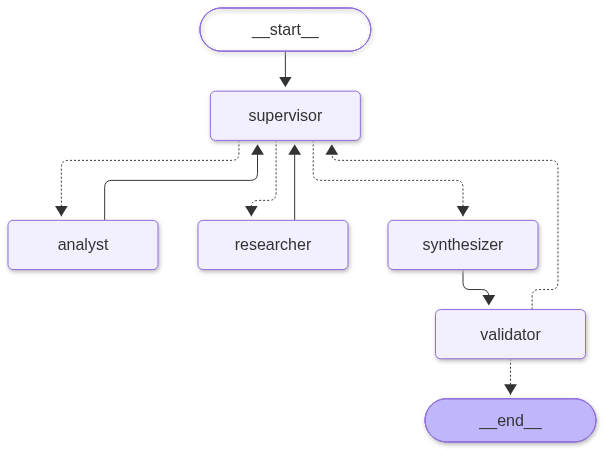

In [2]:
display(Image(filename="docs/graph.png"))

## 2. Ejecución real
La pregunta obliga a usar dos dominios: **investigación** (datos de informes y reseñas) y **cómputo** (crecimientos y sentimiento).

Modelo usado: el definido en `LLM_MODEL` (p. ej. `google_genai:gemini-3.5-flash-lite`).

In [3]:
# Autocontenida: funciona aunque no se haya ejecutado la celda de imports.
import os
from dotenv import load_dotenv
from main import DEMO_QUESTION, run

load_dotenv()
HAS_KEY = any(os.getenv(k) for k in ("GOOGLE_API_KEY", "ANTHROPIC_API_KEY", "OPENAI_API_KEY"))
if HAS_KEY:
    final = run(DEMO_QUESTION)
else:
    final = None
    print("Define GOOGLE_API_KEY (o ANTHROPIC_API_KEY) en .env para ejecutar el flujo real.")


👤 Usuario: Investiga la evolución de NovaPay durante 2024: ¿cuánto crecieron los usuarios activos mensuales y los ingresos entre Q1 y Q4 (porcentaje total y por trimestre)? Además, compara el sentimiento de las reseñas de usuarios de Q3 frente a Q4 y explica qué pudo causar la diferencia.

(cada llamada al LLM puede tardar 10-25 s; la ejecución completa, varios minutos)



🧭 supervisor (paso 1) → researcher
   motivo: La pregunta requiere buscar datos financieros (usuarios activos e ingresos por trimestre) y las reseñas literales de Q3 y Q4 de NovaPay. El researcher debe iniciar la tarea recopilando toda esta información.
   instrucción: Busca los datos de NovaPay para el año 2024: usuarios activos mensuales (MAU) e ingresos desglosados por trimestre (Q1, Q2, Q3 y Q4). Además, recupera textualmente las reseñas de los usuarios de Q3 y Q4 para el posterior análisis de sentimiento.

   … researcher trabajando


   ↳ researcher llama search_knowledge_base({'query': 'NovaPay 2024 MAU ingresos Q1 Q2 Q3 Q4'})


   ↳ researcher llama search_knowledge_base({'query': 'NovaPay Q3 2024 informe ingresos usuarios reseñas'})


   ↳ researcher llama search_knowledge_base({'query': 'reseñas Q3 Q4 NovaPay'})


   ↳ researcher llama search_knowledge_base({'query': 'Reseñas Q4 2024 NovaPay'})


... (7 outputs left out)

📊 analyst usó ['growth_rate', 'growth_rate', 'sentiment_analysis', 'sentiment_analysis']
   ## Resultados
   - **Crecimiento total MAU (Q1→Q4):** +43.33% (growth_rate)
   - **Crecimiento trimestral MAU:** 
     - Q1→Q2: +15.00%
     - Q2→Q3: +9.42%
     - Q3→Q4: +13.91% (growth_rate)
   - **Crecimiento total de Ingresos (Q1→Q4):** +54.17% (growth_rate)
   - **Crecimiento trimestral de Ingresos:** 
     - Q1→Q2: +16.67%
     - Q2→Q3: +8.93%
     - Q3→Q4: +21.31% (growth_rate)
   - **Sentimiento Q3:** Media de -0.373 (20% positivos, 60% negativos, 20% neutros) (sentiment_analysis)
   - **Sentimiento Q4:** Media de +0.324 (60% positivos, 20% negativos, 20% neutros) (sentiment_analysis)
   
   ## Interpretación
   NovaPay experimen…



🧭 supervisor (paso 3) → synthesizer
   motivo: El researcher ha recopilado los datos y reseñas necesarios, y el analyst ha calculado los porcentajes de crecimiento y el análisis de sentimiento requerido utilizando las herramientas adecuadas. Se cumplen todas las condiciones de la rúbrica de suficiencia, por lo que es momento de que el synthesizer redacte la respuesta final.
   instrucción: Redacta la respuesta final integrando la evolución trimestral y total de MAU e ingresos de NovaPay en 2024, el análisis comparativo del sentimiento de las reseñas de Q3 frente a Q4 calculado por el analista, y la explicación de las causas de la diferencia (incidencias técnicas en Q3 y campaña navideña/tarjeta virtual en Q4). Asegúrate de citar todas las fuentes.



📝 synthesizer: borrador generado



✅ [validator] APROBADO

Pasos: 3 | revisiones: 0 | llamadas por agente: {'researcher': 1, 'analyst': 1}
A continuación, se presenta la evolución de NovaPay durante el año 2024 en cuanto a usuarios activos mensuales (MAU), ingresos, análisis de sentimiento de las reseñas de usuarios y las causas de sus diferencias, basándose exclusivamente en los datos de las fuentes aportadas.

### 1. Evolución de Usuarios Activos Mensuales (MAU) e Ingresos (Q1 a Q4)

Según los cálculos del analista a partir de los datos de las fuentes [kb-001, kb-002, kb-003, kb-004]:

*   **Usuarios Activos Mensuales (MAU):**
    *   **Q1 2024:** 1.200.000 usuarios [kb-001].
    *   **Q2 2024:** 1.380.000 usuarios [kb-002] (Crecimiento trimestral Q1→Q2 del analista: **+15,00%**).
    *   **Q3 2024:** 1.510.000 usuarios [kb-003] (Crecimiento trimestral Q2→Q3 del analista: **+9,42%**).
    *   **Q4 2024:** 1.720.000 usuarios [kb-004] (Crecimiento trimestral Q3→Q4 del analista: **+13,91%**).
    *   **Crecimiento total 

## 3. Estado compartido: trazabilidad por agente

In [4]:
from IPython.display import Markdown, display

if final:
    print(f"Pasos del supervisor: {final['step_count']} | revisiones: {final['revision_count']} | llamadas: {final['agent_calls']}")
    for c in final["contributions"]:
        print(f"- paso {c['step']:>2} · {c['agent']:<10} · herramientas={c['tools_used']}")
    display(Markdown(final["final_answer"]))

Pasos del supervisor: 3 | revisiones: 0 | llamadas: {'researcher': 1, 'analyst': 1}
- paso  1 · researcher · herramientas=['search_knowledge_base', 'search_knowledge_base', 'search_knowledge_base', 'search_knowledge_base', 'search_knowledge_base']
- paso  2 · analyst    · herramientas=['growth_rate', 'growth_rate', 'sentiment_analysis', 'sentiment_analysis']


A continuación, se presenta la evolución de NovaPay durante el año 2024 en cuanto a usuarios activos mensuales (MAU), ingresos, análisis de sentimiento de las reseñas de usuarios y las causas de sus diferencias, basándose exclusivamente en los datos de las fuentes aportadas.

### 1. Evolución de Usuarios Activos Mensuales (MAU) e Ingresos (Q1 a Q4)

Según los cálculos del analista a partir de los datos de las fuentes [kb-001, kb-002, kb-003, kb-004]:

*   **Usuarios Activos Mensuales (MAU):**
    *   **Q1 2024:** 1.200.000 usuarios [kb-001].
    *   **Q2 2024:** 1.380.000 usuarios [kb-002] (Crecimiento trimestral Q1→Q2 del analista: **+15,00%**).
    *   **Q3 2024:** 1.510.000 usuarios [kb-003] (Crecimiento trimestral Q2→Q3 del analista: **+9,42%**).
    *   **Q4 2024:** 1.720.000 usuarios [kb-004] (Crecimiento trimestral Q3→Q4 del analista: **+13,91%**).
    *   **Crecimiento total (Q1→Q4):** El analista calcula un crecimiento del **+43,33%**.

*   **Ingresos:**
    *   **Q1 2024:** 4,8 millones de euros [kb-001].
    *   **Q2 2024:** 5,6 millones de euros [kb-002] (Crecimiento trimestral Q1→Q2 del analista: **+16,67%**).
    *   **Q3 2024:** 6,1 millones de euros [kb-003] (Crecimiento trimestral Q2→Q3 del analista: **+8,93%**).
    *   **Q4 2024:** 7,4 millones de euros [kb-004] (Crecimiento trimestral Q3→Q4 del analista: **+21,31%**).
    *   **Crecimiento total (Q1→Q4):** El analista calcula un crecimiento del **+54,17%**.

---

### 2. Comparación del Sentimiento de las Reseñas (Q3 vs. Q4)

El análisis de las reseñas de los usuarios muestra un cambio notable entre el tercer y el cuarto trimestre:

*   **Q3 2024:** 
    *   **Puntuación media de sentimiento:** El analista calcula una media de **-0,373** (con un desglose de un 20% de opiniones positivas, un 60% negativas y un 20% neutras).
    *   **Valoración media en tiendas de apps:** 3,7 sobre 5 [kb-008].
    *   **Ejemplos de reseñas textuales:** *'La caída de agosto fue terrible, no pude pagar en el supermercado.'*, *'App lenta y con errores después de la actualización.'*, *'Buena idea pero el soporte es malo.'*, *'Funciona bien para dividir gastos con amigos.'*, y *'Pésima comunicación durante la caída, muy decepcionado.'* [kb-006].
*   **Q4 2024:** 
    *   **Puntuación media de sentimiento:** El analista calcula una media de **+0,324** (con un desglose de un 60% de opiniones positivas, un 20% negativas y un 20% neutras).
    *   **Valoración media en tiendas de apps:** 4,4 sobre 5 [kb-008].
    *   **Ejemplos de reseñas textuales:** *'La tarjeta virtual es excelente, rápida y muy fácil de usar.'*, *'Me encanta la app, las notificaciones de gasto son útiles.'*, *'El soporte es lento y tardaron una semana en responder, muy frustrante.'*, *'Buena app pero las comisiones internacionales son caras.'*, y *'Increíble experiencia, la recomiendo a todos mis amigos.'* [kb-005].

---

### 3. Causas de la Diferencia

La diferencia en el sentimiento y en la satisfacción de los usuarios entre ambos trimestres se debe a los siguientes factores:
*   **En Q3:** El sentimiento negativo se debió principalmente a incidencias técnicas graves, destacando la **caída del servicio el 14 de agosto (durante 6 horas) que afectó a 300.000 usuarios** [kb-003], sumado a problemas de lentitud tras una actualización y a una pésima comunicación por parte de la empresa [kb-006].
*   **En Q4:** La recuperación a un sentimiento positivo y el incremento en las valoraciones se debieron a los inductores de crecimiento del trimestre: la **campaña de Navidad** y el **lanzamiento de la tarjeta virtual** [kb-004], elementos que mejoraron la experiencia de uso [kb-005].

---

### Limitaciones
*   El análisis de sentimiento se ha realizado sobre muestras reducidas de reseñas (n=5 por trimestre), por lo que podría no reflejar la opinión de la totalidad de la base de usuarios.
*   Los datos de ingresos y MAU son agregados trimestrales y no permiten un desglose mensual detallado del impacto de las incidencias.

## 4. (Sin API key) Mismo grafo con un LLM guionizado

Para comprobar la topología y las condiciones de parada sin red: las decisiones del LLM están guionizadas en `tests/fake_llm.py`, pero **las herramientas se ejecutan de verdad** y el grafo es exactamente el mismo. Incluye un rechazo del validador que fuerza una ronda de refinamiento.

In [5]:
from graph import build_graph
from main import run
from tests.test_graph_offline import make_llm

offline = run("Crecimiento de MAU de NovaPay Q1→Q4 2024 y sentimiento de reseñas", app=build_graph(make_llm()))
print()
for c in offline["contributions"]:
    print(f"- paso {c['step']:>2} · {c['agent']:<10} · herramientas={c['tools_used']}")


👤 Usuario: Crecimiento de MAU de NovaPay Q1→Q4 2024 y sentimiento de reseñas

(cada llamada al LLM puede tardar 10-25 s; la ejecución completa, varios minutos)

🧭 supervisor (paso 1) → researcher
   motivo: toca researcher
   instrucción: haz tu parte

   … researcher trabajando


   ↳ researcher llama search_knowledge_base({'query': 'usuarios activos Q1 Q4 2024'})


🔎 researcher usó ['search_knowledge_base']
   ## Hallazgos
   - MAU Q1 1.200.000 [kb-001], Q4 1.720.000 [kb-004]

🧭 supervisor (paso 2) → analyst
   motivo: toca analyst
   instrucción: haz tu parte

   … analyst trabajando


   ↳ analyst llama growth_rate({'values': [1200000, 1720000], 'labels': ['Q1', 'Q4']})


📊 analyst usó ['growth_rate']
   ## Resultados
   - Crecimiento MAU: +43.33% (growth_rate)

🧭 supervisor (paso 3) → synthesizer
   motivo: toca synthesizer
   instrucción: haz tu parte

📝 synthesizer: borrador generado

✅ [validator] RECHAZADO (para analyst) Falta ejecutar con la herramienta del analista: análisis de sentimiento de reseñas (herramienta: sentiment_analysis). Falta el análisis de sentimiento.

🧭 supervisor (paso 4) → analyst
   motivo: toca analyst
   instrucción: calcula el sentimiento

   … analyst trabajando


   ↳ analyst llama sentiment_analysis({'texts': ['excelente', 'terrible caída']})


📊 analyst usó ['sentiment_analysis']
   ## Resultados
   - Sentimiento medio calculado (sentiment_analysis)

🧭 supervisor (paso 5) → synthesizer
   motivo: toca synthesizer
   instrucción: haz tu parte

📝 synthesizer: borrador generado

✅ [validator] APROBADO

Pasos: 5 | revisiones: 1 | llamadas por agente: {'researcher': 1, 'analyst': 2}
Borrador v2: MAU +43.33% [kb-001][kb-004]; sentimiento calculado por el analista.

- paso  1 · researcher · herramientas=['search_knowledge_base']
- paso  2 · analyst    · herramientas=['growth_rate']
- paso  4 · analyst    · herramientas=['sentiment_analysis']
